# A default model, fitted to Freddie Mac's loans

The same 2% sample of Freddie Mac's 30-year fixed-rate loans, 1999 to 2025, as the prepayment model (`freddie_prepayment_model.ipynb`;
`load_freddie_data/README.md` says how the database is made).

A loan **defaults** in the first month that it is six months delinquent, unless it is in forbearance or delinquent because of a disaster (most loans
that were that delinquent in 2020 and 2021 were, in the COVID-19 forbearance, and caught up), or that the home is taken by foreclosure, or that the loan
ends in a short sale, a third-party sale, an REO sale or a sale of the note while it is not being paid. That is near what Freddie calls a credit event in
the bonds that share its losses. A loan defaults once.

The model is in three parts (`lib/freddie_default.lsp`):

- **what became of the loans that defaulted**: how much was sold at a loss, and how much was paid off or caught up instead;
- **how many default**: the chance that a loan that has not defaulted defaults in a month, weighted by its balance, so that over a pool it is the
  monthly default rate (mdr), and the CDR is 1 - (1 - mdr)^12;
- **what is lost**: the severity of a sale, the loss over the balance, where the loss is the balance, the unpaid interest and the costs, less what the
  home sold for and what mortgage insurance and others paid.

In an agency deal Freddie guarantees the loans, so a default reaches the bonds as a prepayment (Freddie buys the loan out of the pool) and the loss is
Freddie's. The losses matter to a deal of loans with no guarantee, and to the bonds that share Freddie's losses.

The models are fitted to the loans with a `sample_bucket` below 80, in the months before 2019, and tried on the other loans.

In [1]:
(define conn (sqlite-open "/Users/morris/freddie_data/freddie_loans.db"))

conn

## What became of the loans that defaulted

A row for each year that loans defaulted in: the share of their balance, in percent, that was sold at a loss, sold as a note while it was not being
paid (Freddie reports no loss for those), paid off, sold as a note after it was being paid again (most often after a modification), and is not over yet.
The **severity** is of the sales at a loss; the **loss given default** is the losses over all that defaulted, sold or not. The years near the end are not
over: what is still going has no loss yet.

In [2]:
(display-table (default-outcomes conn)
               '(("balance" ",.0f") ("sold at a loss" ".1f") ("note sold" ".1f") ("paid off" ".1f") ("sold, paying" ".1f") ("not over" ".1f")
                 ("severity" ".1f") ("months to the sale" ".1f") ("loss given default" ".1f"))
               :max-rows #f)

| year | defaults | balance | sold at a loss | note sold | paid off | sold, paying | not over | severity | months to the sale | loss given default |
|:---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 1999 | 1 | 125,347 | 0.0 | 0.0 | 0.0 | 0.0 | 0.0 |  |  | 0.0 |
| 2000 | 30 | 3,004,217 | 40.2 | 0.0 | 21.0 | 0.0 | 0.0 | 16.6 | 10.5 | 5.4 |
| 2001 | 103 | 10,349,659 | 52.7 | 0.0 | 25.8 | 0.6 | 0.2 | 14.6 | 20.7 | 5.8 |
| 2002 | 218 | 24,314,756 | 45.7 | 0.4 | 30.7 | 2.8 | 0.9 | 19.5 | 18.4 | 6.1 |
| 2003 | 304 | 31,758,157 | 56.0 | 0.0 | 23.7 | 1.6 | 0.6 | 21.8 | 16.1 | 9.6 |
| 2004 | 282 | 30,496,310 | 65.9 | 0.0 | 21.3 | 2.4 | 0.0 | 21.3 | 14.7 | 11.1 |
| 2005 | 238 | 25,646,343 | 62.0 | 1.7 | 31.7 | 4.0 | 0.0 | 28.3 | 22.4 | 17.1 |
| 2006 | 283 | 34,087,554 | 55.5 | 0.8 | 32.9 | 5.5 | 0.9 | 30.0 | 21.8 | 16.1 |
| 2007 | 384 | 50,578,999 | 73.1 | 0.2 | 17.8 | 5.3 | 1.3 | 36.1 | 17.3 | 23.4 |
| 2008 | 974 | 172,372,241 | 73.9 | 3.0 | 8.4 | 5.9 | 1.8 | 48.2 | 22.0 | 30.8 |
| 2009 | 2790 | 533,264,034 | 64.4 | 3.2 | 13.0 | 10.2 | 2.1 | 52.8 | 25.3 | 31.4 |
| 2010 | 3129 | 596,489,332 | 59.5 | 2.6 | 18.1 | 12.9 | 2.6 | 49.8 | 21.5 | 27.7 |
| 2011 | 2267 | 409,995,981 | 63.8 | 3.0 | 15.6 | 11.4 | 2.4 | 44.9 | 19.7 | 27.0 |
| 2012 | 1858 | 321,103,139 | 59.3 | 4.4 | 16.9 | 11.5 | 4.2 | 38.7 | 15.1 | 22.2 |
| 2013 | 1167 | 185,393,890 | 55.7 | 3.6 | 18.8 | 16.1 | 4.3 | 39.0 | 15.5 | 21.3 |
| 2014 | 813 | 121,153,595 | 47.0 | 9.9 | 19.9 | 15.6 | 6.1 | 37.2 | 15.2 | 17.3 |
| 2015 | 629 | 91,509,715 | 47.5 | 6.0 | 22.2 | 18.4 | 5.5 | 35.0 | 13.9 | 16.5 |
| 2016 | 528 | 79,166,644 | 42.2 | 6.3 | 25.0 | 19.2 | 5.5 | 31.5 | 14.8 | 13.2 |
| 2017 | 428 | 64,025,919 | 36.9 | 6.9 | 27.7 | 21.6 | 6.0 | 28.9 | 13.7 | 10.7 |
| 2018 | 419 | 67,602,843 | 23.5 | 5.5 | 34.8 | 19.9 | 14.6 | 25.1 | 15.8 | 5.7 |
| 2019 | 360 | 57,516,124 | 26.7 | 6.4 | 28.8 | 19.6 | 16.0 | 25.1 | 18.8 | 6.6 |
| 2020 | 377 | 70,818,380 | 7.9 | 7.7 | 34.5 | 9.5 | 39.4 | 25.9 | 25.7 | 2.1 |
| 2021 | 608 | 136,132,332 | 2.4 | 1.2 | 34.1 | 7.7 | 53.9 | 17.2 | 20.3 | 0.4 |
| 2022 | 606 | 138,335,997 | 5.1 | 1.4 | 24.1 | 6.8 | 59.2 | 11.3 | 16.1 | 0.5 |
| 2023 | 529 | 124,854,662 | 4.2 | 3.7 | 20.6 | 6.1 | 59.7 | 8.9 | 13.1 | 0.3 |
| 2024 | 627 | 152,720,224 | 6.3 | 2.1 | 17.5 | 1.4 | 69.4 | 14.6 | 9.6 | 0.7 |
| 2025 | 648 | 155,121,998 | 4.1 | 0.6 | 8.9 | 0.1 | 85.6 | 7.4 | 5.1 | 0.2 |
| 2026 | 202 | 52,578,067 | 0.1 | 0.0 | 2.3 | 0.0 | 97.6 |  |  | 0.0 |

## How many default

In [3]:
(define defaults (fit-default-model (freddie-default-months conn "sample_bucket < 80 AND period < '2019-01-01'")))
(display (model-report defaults))

Piecewise-linear spline model, with a logistic link, predicting y:
  predictors = 12
  credit_score: knots 620, 680, 740
  current_ltv: knots 60, 80, 100
  loan_age: knots 12, 24, 48, 96
  dti: knots 36, 45
  sato: knots (none -- plain linear)
  incentive_bp: knots -100, 0, 100
  loan_size_k: knots 100, 200, 300
  investor: knots (none -- plain linear)  [only 2 distinct value(s) seen -- consider 'categorical]
  second_home: knots (none -- plain linear)  [only 2 distinct value(s) seen -- consider 'categorical]
  cash_out: knots (none -- plain linear)  [only 2 distinct value(s) seen -- consider 'categorical]
  refinance: knots (none -- plain linear)  [only 2 distinct value(s) seen -- consider 'categorical]
  one_borrower: knots (none -- plain linear)  [only 2 distinct value(s) seen -- consider 'categorical]

Coefficients (on the expanded basis):
  term                       coefficient     std error    z value    p value
  intercept                     -13.2649      0.564966     -23.48  

The CDR of the loans the model was not fitted to, month by month, and what it said; and how far it is, on average over the months, before 2019 and
from 2019 on.

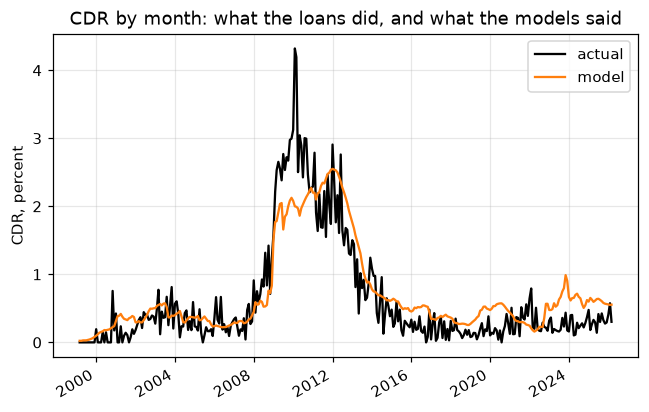

In [4]:
(define test-months (freddie-default-months conn "sample_bucket >= 80"))
(plot-rate-by-month (list (list "model" defaults test-months)) "CDR")

In [5]:
(display-table (rate-misses (list (list "model" defaults test-months)) (date 2019 1 1) "CDR")
               '(("before 2019-01-01" ".2f") ("from 2019-01-01 on" ".2f")))

| model | before 2019-01-01 | from 2019-01-01 on |
|:---|---:|---:|
| model | 0.28 | 0.29 |

What the model says a typical loan defaults at (`typical-default-loan`: three years old, $250,000, 36% debt-to-income, two borrowers buying a home to
live in), against its loan-to-value now, for three credit scores.

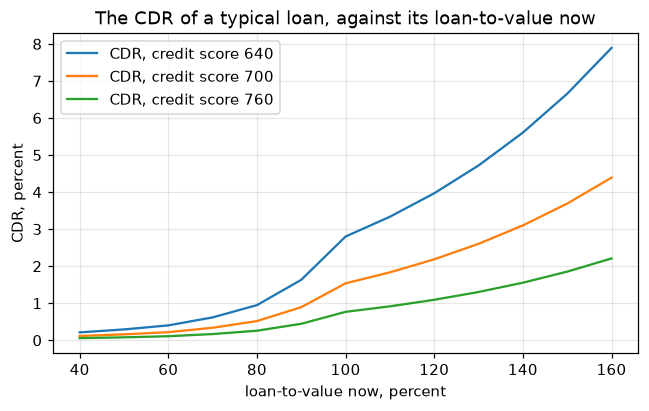

In [6]:
(plot-default-ltv-curves defaults)

## What is lost

In [7]:
(define severity (fit-severity-model (freddie-liquidations conn "sample_bucket < 80 AND period < '2019-01-01'")))
(display (model-report severity))

Piecewise-linear spline model, predicting y:
  predictors = 5
  ltv_at_default: knots 60, 80, 100, 120
  loan_size_k: knots 100, 200
  mi_percent: knots (none -- plain linear)
  months_since_default: knots 12, 24, 36
  investor: knots (none -- plain linear)  [only 2 distinct value(s) seen -- consider 'categorical]

Coefficients (on the expanded basis):
  term                             coefficient     std error    t value    p value
  intercept                           0.245299     0.0657477      3.731   0.000192
  ltv_at_default                    0.00958755    0.00113275      8.464   3.08e-17
  ltv_at_default (knot 60)         -0.00427967    0.00157648     -2.715    0.00665
  ltv_at_default (knot 80)         0.000358206    0.00104788     0.3418      0.732
  ltv_at_default (knot 100)        -0.00192139   0.000942329     -2.039     0.0415
  ltv_at_default (knot 120)        -0.00201656   0.000740861     -2.722    0.00651
  loan_size_k                      -0.00611714   0.000310931    

The severity of the sales of the loans the model was not fitted to, year by year, and what it said, in percent.

In [8]:
(display-table (severity-by-year severity (freddie-liquidations conn "sample_bucket >= 80"))
               '(("actual severity" ".1f") ("predicted severity" ".1f"))
               :max-rows #f)

| year | actual severity | predicted severity |
|:---|---:|---:|
| 2000-01-01 | 0.0 | 64.8 |
| 2001-01-01 | 19.5 | 33.7 |
| 2002-01-01 | 7.9 | 31.8 |
| 2003-01-01 | 12.8 | 34.2 |
| 2004-01-01 | 14.4 | 25.9 |
| 2005-01-01 | 27.6 | 35.9 |
| 2006-01-01 | 26.2 | 38.2 |
| 2007-01-01 | 19.9 | 32.1 |
| 2008-01-01 | 30.4 | 28.8 |
| 2009-01-01 | 40.9 | 34.5 |
| 2010-01-01 | 46.8 | 39.5 |
| 2011-01-01 | 49.0 | 44.2 |
| 2012-01-01 | 48.2 | 45.1 |
| 2013-01-01 | 41.2 | 48.3 |
| 2014-01-01 | 52.1 | 52.3 |
| 2015-01-01 | 54.7 | 50.4 |
| 2016-01-01 | 45.1 | 45.9 |
| 2017-01-01 | 47.0 | 49.2 |
| 2018-01-01 | 31.5 | 42.7 |
| 2019-01-01 | 42.4 | 43.1 |
| 2020-01-01 | 31.3 | 37.0 |
| 2021-01-01 | 49.9 | 47.2 |
| 2022-01-01 | 44.7 | 50.7 |
| 2023-01-01 | 23.5 | 44.0 |
| 2024-01-01 | 9.5 | 30.9 |
| 2025-01-01 | 38.4 | 46.0 |

What the model says the severity of a typical sale is (`typical-liquidation`: $200,000, no mortgage insurance, sold a year and a half after the
default), against the loan-to-value when the loan defaulted.

In [9]:
(display-table (severity-ltv-curve severity) '(("severity" ".1f")) :max-rows #f)

| ltv\_at\_default | severity |
|---:|---:|
| 40 | 13.0 |
| 50 | 22.6 |
| 60 | 32.2 |
| 70 | 37.5 |
| 80 | 42.8 |
| 90 | 48.4 |
| 100 | 54.1 |
| 110 | 57.9 |
| 120 | 61.6 |
| 130 | 63.3 |
| 140 | 65.1 |
| 150 | 66.8 |
| 160 | 68.5 |